<a href="https://colab.research.google.com/github/WeridFire/QuantumComputing/blob/main/assignment1/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1 - State‑Vector Quantum Computer Simulator
You will build a minimal state‑vector simulator and use it to simulate a 2‑qubit Bell circuit. A state‑vector simulator represents the quantum state as a complex vector and applies gates as matrices.

> Convention: We use computational basis ordering |q0 q1> with q0 as the most significant qubit (MSB). The basis is |00>,|01>,|10>,|11> → indices [0,1,2,3].

## Task 1.1 - State‑vector representation
Getting the basis and normalization right prevents subtle bugs later (wrong amplitudes, swapped qubits). This is the foundation for applying gates and interpreting measurements.

> What the code does: Creates and normalizes a 4‑dimensional complex vector for a 2‑qubit system, initializing it to |00> or |0>.

In [ ]:
import numpy as np

DTYPE = np.complex128

def ket00():
    """Return |00> as a length‑4 complex column vector."""
    v = np.zeros(4, dtype=DTYPE)
    v[0] = 1.0
    return v

def normalize(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v)
    if n == 0:
        raise ValueError("Zero vector cannot be normalized.")
    return v / n

# Example
psi = ket00()
assert np.isclose(np.linalg.norm(psi), 1.0)

> What to include. A short sentence describing your basis ordering and how you map bitstrings to indices.

### Our Solution

We adopt the standard computational basis ordering $\vert{}q_0 q_1\rangle$, where $q_0$ is the most significant qubit (MSB) and $q_1$ is the least significant qubit (LSB). Each two-qubit basis state directly maps to its integer array index via the standard binary representation.

## Task 1.2 - Quantum gate implementation

Gates are linear operators. Building them once and applying correctly to the target qubit makes later circuits easy to reason about and unit‑test.

> What the code does: Defines Hadamard and CNOT matrices and utilities to apply them in the 2‑qubit basis.

In [ ]:
# 1‑qubit and 2‑qubit gate definitions (matrix form)
I2 = np.array([[1, 0], [0, 1]], dtype=DTYPE)
H  = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=DTYPE)

# CNOT with control = q0 (MSB), target = q1 (LSB) in basis |q0 q1>
CNOT_01 = np.array([
    [1,0,0,0],
    [0,1,0,0],
    [0,0,0,1],
    [0,0,1,0]
], dtype=DTYPE)

# Expand a 1‑qubit unitary U to a 2‑qubit operator acting on target qubit t in |q0 q1> order
# t = 0 applies to q0 (MSB); t = 1 applies to q1 (LSB)

def expand_1q(U: np.ndarray, t: int) -> np.ndarray:
    if t == 0:   # act on q0 (MSB)
        return np.kron(U, I2)
    elif t == 1: # act on q1 (LSB)
        return np.kron(I2, U)
    else:
        raise ValueError("target index must be 0 or 1")

# Apply a gate matrix to a state vector

def apply(U: np.ndarray, psi: np.ndarray) -> np.ndarray:
    return U @ psi

# Quick unit tests
assert np.allclose(H.conj().T @ H, I2)
assert np.allclose(CNOT_01.conj().T @ CNOT_01, np.eye(4))

> What to include. Briefly justify your control/target convention for CNOT and how it matches the basis ordering.

### Our Solution

We define the CNOT matrix using the convention where $q_0$ is the control and $q_1$ is the target. In our $|q_0 q_1\rangle$ basis ordering, this results in a block-diagonal matrix:

*   If $q_0 = 0$ (indices 0 and 1), the identity $I_2$ is applied to $q_1$.
*   If $q_0 = 1$ (indices 2 and 3), the Pauli-X gate is applied to $q_1$.

This leads to the matrix representation (also present in the code above):
$$\text{CNOT}_{01} = \begin{pmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0 \end{pmatrix}$$


##Task 1.3 - Circuit simulation: Bell state

The Bell state is the simplest non‑separable state. Simulating it shows how interference from H, combined with a single controlled operation, produces entanglement.

> What the code does: Applies H on q0 then CNOT(q0→q1) to produce |Φ+> = (|00>+|11>)/√2.

In [ ]:
def bell_state() -> np.ndarray:
    psi = ket00()
    # H on q0 (MSB), then CNOT(control=q0, target=q1)
    psi = apply(expand_1q(H, t=0), psi)
    psi = apply(CNOT_01, psi)
    return normalize(psi)

psi_bell = bell_state()
print("Bell state vector:", np.round(psi_bell, 6))
# Expected amplitudes (up to a global phase): [1/√2, 0, 0, 1/√2]

Bell state vector: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]


> What to include. Print the final state and confirm it matches ( |00> + |11> ) / √2 up to global phase.

### Our Solution
Compiling the code above the result is the following:

```
Bell state vector: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]
```

which correspond exactly to:

( |00> + |11> ) / √2

##Task 1.4 - Output, verification, and circle‑plot comparison

Bridge amplitudes -> measurement outcomes, and verify your simulator against expectations. Visualization connects algebra to intuitive structure.

> What the code does: Samples bitstrings from the state, plots a histogram, and compare to earlier work.

{'00': 4983, '01': 0, '10': 0, '11': 5017}


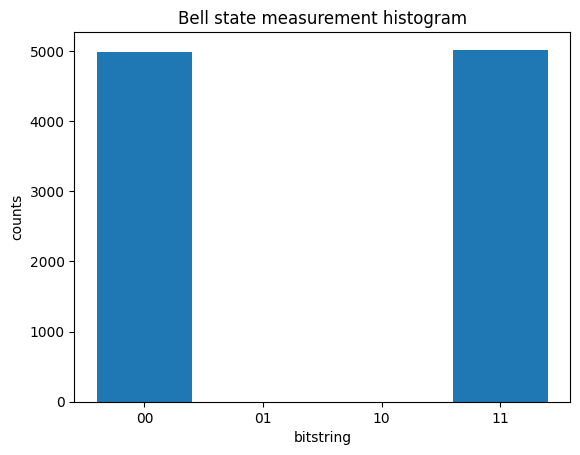

In [ ]:
import matplotlib.pyplot as plt

BITSTR = ["00","01","10","11"]

def sample_bitstrings(psi: np.ndarray, shots: int = 10_000, seed: int = 7):
    rng = np.random.default_rng(seed)
    probs = np.abs(psi)**2
    idx = rng.choice(4, size=shots, p=probs)
    return idx

# Sample from Bell state
shots = 10_000
idx = sample_bitstrings(psi_bell, shots=shots)

# Make histogram
counts = {b: int(np.sum(idx == i)) for i, b in enumerate(BITSTR)}
print(counts)
plt.bar(counts.keys(), counts.values())
plt.xlabel("bitstring"); plt.ylabel("counts"); plt.title("Bell state measurement histogram")
plt.show()

> What to include:
   - Circle‑notation visualization. Use your lecture function to visualize (in circle notation, see here, for instance) psi_bell

  - Compare and reflect. Do the counts match expectations within sampling error? How does the circle plot show two dominant components |00> and |11> and their relative phase?

Let's first setup enviroment for the lecture code

In [ ]:
!pip install qiskit

QbitSystem Class with his functions

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

class QubitSystem:
    def __init__(self, statevector: np.ndarray, label: str = "Qubit System"):
        self.label = label
        self.set_statevector(statevector)

    def set_statevector(self, statevector: np.ndarray):
        sv = np.asarray(statevector, dtype=np.complex128).flatten()
        if sv.ndim != 1:
            raise ValueError("Statevector must be 1D.")
        n_states = sv.size
        n_qubits = int(round(math.log2(n_states)))
        if 2**n_qubits != n_states:
            raise ValueError("Length must be a power of 2.")
        # Defensive normalization (harmless if already normalized)
        norm = np.linalg.norm(sv)
        if norm != 0 and not np.isclose(norm, 1.0):
            sv = sv / norm

        self.n_qubits = n_qubits
        self.n_states = n_states
        self.amps  = sv
        self.prob  = np.abs(sv)**2
        self.phase = np.angle(sv)

    def viz_circle(self, max_cols: int = 8, figsize_scale: float = 2.3):
        cols = max(1, min(max_cols, self.n_states))
        rows = int(math.ceil(self.n_states / cols))

        fig, axes = plt.subplots(
            rows, cols,
            figsize=(cols*figsize_scale, rows*(figsize_scale+0.2))
        )
        axes = np.atleast_2d(axes)

        def bitstr(i: int, n: int) -> str:
            return format(i, f"0{n}b")

        for idx in range(rows * cols):
            r, c = divmod(idx, cols)
            ax = axes[r, c]
            ax.set_aspect("equal")
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)
            ax.axis("off")

            if idx >= self.n_states:
                ax.set_visible(False)
                continue

            # Outer reference circle
            ax.add_patch(plt.Circle((0.5, 0.5), 0.48, fill=False, lw=1.0, alpha=0.5))

            # Filled disk: radius ∝ sqrt(probability) so area ∝ probability
            radius = 0.48 * np.sqrt(self.prob[idx])
            ax.add_patch(plt.Circle((0.5, 0.5), radius, alpha=0.25))

            # Phase arrow
            angle = self.phase[idx]
            L = 0.45
            x2 = 0.5 + L * np.cos(angle)
            y2 = 0.5 + L * np.sin(angle)
            ax.arrow(0.5, 0.5, x2 - 0.5, y2 - 0.5,
                     head_width=0.03, head_length=0.05, length_includes_head=True)

            ax.set_title(f"|{bitstr(idx, self.n_qubits)}⟩", fontsize=10)

        fig.suptitle(self.label, fontsize=12)
        plt.tight_layout()
        plt.show()

Inverse function too:

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

def sv_from_circ(circ: QuantumCircuit) -> np.ndarray:
    """Extract a numpy complex vector from a Qiskit QuantumCircuit."""
    sv = Statevector(circ)
    return np.asarray(sv, dtype=np.complex128)

### Our Solution


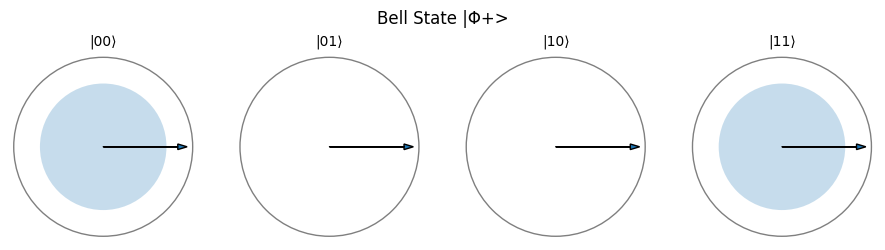

Measurement counts: {'00': 4983, '01': 0, '10': 0, '11': 5017}
Theoretical probability for |00>: 0.50
Theoretical probability for |11>: 0.50


In [ ]:
# Initialize the QubitSystem with our psi_bell calculated in Task 1.3
bell_system = QubitSystem(psi_bell, label="Bell State |Φ+>")

# Visualize using circle notation
bell_system.viz_circle()

# Verification analysis
print(f"Measurement counts: {counts}")
print(f"Theoretical probability for |00>: {np.abs(psi_bell[0])**2:.2f}")
print(f"Theoretical probability for |11>: {np.abs(psi_bell[3])**2:.2f}")

> Here the phase convention is different from the one adopted in class; a 0 randiant phase correspond to the arrow pointing right, exactly if it was a 0 angle in a cartesian plan.

### Comparison and Reflection

The theoretical probability for a Bell state $|\Phi^+\rangle = \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$ is $0.5$ for both $|00\rangle$ and $|11\rangle$, and $0$ for $|01\rangle$ and $|10\rangle$. Our sampled counts (4983 for $|00\rangle$ and 5017 for $|11\rangle$) result in experimental probabilities of 0.498 and 0.502 respectively. These are coherent with the standard sampling error (which is approximately $1/\sqrt{10000} = 0.01$ for 10,000 mesurements).

About the circle plot:
*   Dominant Components: The plot shows two large filled disks for $|00\rangle$ and $|11\rangle$, while $|01\rangle$ and $|10\rangle$ have empty circles. This visually confirms the state is a superposition.
*   Relative Phase: The arrows in both the $|00\rangle$ and $|11\rangle$ circles point in the same direction (angle 0).

# Task 2 - State‑Vector SWAP Test
Estimate the fidelity between two 1-qubit states using your state-vector simulator and the SWAP test, then verify against the direct inner product. We use output for the control bit (as in the lecture) and keep MSB-first ordering.Fidelity (pure states): ${F(\vert{}\psi\rangle, \vert{}\phi\rangle) = \vert{}\langle\psi\vert{}\phi\rangle\vert{}^2}$. In the SWAP test, $F = 1 - 2\,P(\text{output} = 1)$.

### Some helper functions

> Note that this is the exact code form the instruction, it just serves as exemple does not practically run



In [ ]:
def expand_1q_n(U: np.ndarray, t: int, n: int) -> np.ndarray:
    op = np.array([[1]], dtype=U.dtype)
    for q in range(n):
        op = np.kron(op, U if q == t else I2)
    return op
# Note: ancilla = control qbit
# Apply CSWAP, with ancilla as control
P0 = np.array([[1,0],[0,0]], dtype=DTYPE)  # |0><0| on ancilla
P1 = np.array([[0,0],[0,1]], dtype=DTYPE)  # |1><1| on ancilla
SWAP_A0_B0 = np.array([
    [1,0,0,0],
    [0,0,1,0],
    [0,1,0,0],
    [0,0,0,1]
], dtype=DTYPE)  # SWAP on A0 and B0
CSWAP = (np.kron(P0, np.eye(4)) + np.kron(P1, SWAP_A0_B0)) # CSWAP with ancilla as control

Initial state (|output A0 B0>):



```python
init = np.kron(np.array([1,0], dtype=DTYPE), np.kron(psi, phi))  # |0>_output ⊗ |ψ>_A ⊗ |φ>_B
```



H – exchange – H on the output (MSB):




```
U_Ho = expand_1q_n(H, t=0, n=3)
state = U_Ho @ init
state = CSWAP @ state
state = U_Ho @ state
```



Readout & fidelity from output bit:





```
probs = np.abs(state)**2
prob_1 = probs[4:].sum()   # indices with output=1
F_hat = 1 - 2*prob_1
```



Exact fidelity check (inner product):



```
F_exact = float(np.abs(np.vdot(psi/np.linalg.norm(psi), phi/np.linalg.norm(phi)))**2)
```



## Our Solution

We test the SWAP test on three pairs of single-qubit states, chosen to cover
the full range of the fidelity:

- $\vert 0\rangle$ and $\vert +\rangle$ : expected $F = 0.5$: partial overlap, the generic case.
- $\vert 0\rangle$ and $\vert 0\rangle$ : expected $F = 1$: identical states, upper bound.
- $\vert 0\rangle$ and $\vert 1\rangle$ : expected $F = 0$: orthogonal states, lower bound.

For each pair we compute the fidelity in three ways:

1. **From the exact state-vector probabilities.** We read $P(\text{out}=1)$
   directly off $\vert\text{amplitudes}\vert^2$ and apply $F = 1 - 2P(1)$.
2. **From sampled measurements.** We draw 10,000 shots from the output qubit
   and use the empirical frequency $\hat{P}(1)$. This mirrors how the SWAP test
   is actually used on hardware, where the state vector is not accessible.
3. **From the direct inner product**, $F = \vert\langle\psi\vert\phi\rangle\vert^2$,
   as the ground truth to check the other two against.

The circuit is the same in all cases: $H$ on the output qubit (MSB), then the
controlled-SWAP on the two data qubits, then $H$ again on the output. Only the
two input states change, so we factor the circuit into a reusable function.

In [ ]:
import numpy as np

def swap_test_state(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Run the SWAP test circuit and return the final 3-qubit state |out A0 B0>."""
    a = a / np.linalg.norm(a)
    b = b / np.linalg.norm(b)
    state = np.kron(np.array([1, 0], dtype=DTYPE), np.kron(a, b))
    U_H0 = expand_1q_n(H, t=0, n=3)   # H on the output qubit (MSB)
    state = apply(U_H0, state)
    state = apply(CSWAP, state)
    state = apply(U_H0, state)
    return state

def fidelity_exact_probs(a, b):
    """Fidelity from the exact state-vector probabilities (no sampling)."""
    probs = np.abs(swap_test_state(a, b))**2
    p1 = probs[4:].sum()          # indices 4..7 = output qubit is |1>
    return 1 - 2*p1, p1

def fidelity_sampled(a, b, shots=10_000, seed=7):
    """Fidelity estimated by sampling the output qubit, as on real hardware."""
    probs = np.abs(swap_test_state(a, b))**2
    probs = probs / probs.sum()   # guard against float drift before rng.choice
    rng = np.random.default_rng(seed)
    idx = rng.choice(8, size=shots, p=probs)
    p1_hat = np.mean(idx >= 4)    # output qubit is the MSB
    return 1 - 2*p1_hat, p1_hat

# --- Test states -------------------------------------------------------------
ket0 = np.array([1, 0], dtype=DTYPE)
ket1 = np.array([0, 1], dtype=DTYPE)
ketp = H @ ket0                       # |+>

cases = [
    ("|0>, |+>  (partial overlap)", ket0, ketp),
    ("|0>, |0>  (identical)",       ket0, ket0),
    ("|0>, |1>  (orthogonal)",      ket0, ket1),
]

print(f"{'case':<30} {'P(1) exact':>11} {'F state-vec':>12} {'F sampled':>10} {'F inner prod':>13}")
print("-"*80)
for name, a, b in cases:
    F_sv, p1 = fidelity_exact_probs(a, b)
    F_hat, _ = fidelity_sampled(a, b)
    F_inner  = float(np.abs(np.vdot(a/np.linalg.norm(a), b/np.linalg.norm(b)))**2)
    print(f"{name:<30} {p1:>11.4f} {F_sv:>12.4f} {F_hat:>10.4f} {F_inner:>13.4f}")

# Consistency check across all three cases
for name, a, b in cases:
    F_sv, _ = fidelity_exact_probs(a, b)
    F_inner = float(np.abs(np.vdot(a/np.linalg.norm(a), b/np.linalg.norm(b)))**2)
    assert np.isclose(F_sv, F_inner, atol=1e-12), f"mismatch for {name}"
print("\nAll cases match the direct inner product within 1e-12.")

# Expected statistical error: F = 1 - 2*P1, so sigma_F = 2*sigma_P1
p1_ref  = fidelity_exact_probs(ket0, ketp)[1]
sigma_F = 2*np.sqrt(p1_ref*(1-p1_ref)/10_000)
print(f"Expected 1-sigma error on the sampled F for the |0>,|+> case: {sigma_F:.4f}")

case                            P(1) exact  F state-vec  F sampled  F inner prod
--------------------------------------------------------------------------------
|0>, |+>  (partial overlap)         0.2500       0.5000     0.4926        0.5000
|0>, |0>  (identical)               0.0000       1.0000     1.0000        1.0000
|0>, |1>  (orthogonal)              0.5000       0.0000    -0.0034        0.0000

All cases match the direct inner product within 1e-12.
Expected 1-sigma error on the sampled F for the |0>,|+> case: 0.0087


### Verification Analysis

The SWAP test maps the overlap between two states onto the statistics of a
single output qubit: interference makes $P(1)$ grow with how *different* the
data states are, giving $P(1) = \tfrac{1}{2}(1 - F)$ and therefore $F = 1 - 2P(1)$.

For all three pairs the fidelity from the exact state-vector probabilities
matches the direct inner product to within $10^{-12}$, which confirms both the
CSWAP construction and the MSB-first ordering — with the output qubit anywhere
else, slicing `probs[4:]` would read the wrong qubit.

The sampled estimate gives $\hat{F} = 0.4926$ for the $\vert 0\rangle, \vert +\rangle$
pair against a true value of $0.5$. Since $F = 1 - 2P(1)$, the error on $F$ is
twice that on $P(1)$: $\sigma_F = 2\sqrt{P(1)(1-P(1))/N} = 0.0087$, so the
observed deviation of $0.0074$ sits below one standard deviation.

Two details of the sampled column are worth noting. The orthogonal case returns
$\hat{F} = -0.0034$: the estimator is unbiased but not bounded to $[0,1]$, so a
fluctuation pushing $\hat{P}(1)$ above $0.5$ sends it negative. The identical
case instead returns exactly $1.0$ with no scatter, because there $P(1) = 0$ is
strictly zero — the outcome is impossible, not merely rare.

# Bonus Exercise - Quantum State Comparison with the Multiqubit SWAP Test

In this bonus exercise, you will design, implement, and analyze a three-qubit-per-register SWAP test in Qiskit to compare two quantum systems:

* a known **reference state** (e.g., $|5\rangle$ on three qubits) encoded in a 3-qubit register $R$, and
* a random state chosen from the computational basis (Task B.1) encoded in a register $L$, then a modified superposition variant (Task B.2). We will refer to this state as the **test state**.

The multi-qubit SWAP test estimates the fidelity $F = |\langle\psi|\phi\rangle|^2$ using an output (control) qubit and the pattern H – exchange – H. Because fidelity is a similarity score, the SWAP test is a core building block for quantum nearest neighbors, quantum clustering, and anomaly detection. Your job is not only to create a working circuit, but also to justify your design and evaluate its effectiveness. <u>We don't expect you to come up with the optimal solution; you can experiment with one or more solutions, argue for their design, and critically assess the results</u>.

In this bonus exercise, you will use <u>Qiskit Simulator</u>.

### Some Useful Code

* **Circuits & registers:** `qiskit.QuantumCircuit`, optional `QuantumRegister`, `ClassicalRegister`.
* **Gates:** some gates you might find useful are `qc.h`, `qc.cx`, `qc.ccx` (Toffoli), `qc.x`. Build SWAP per pair as `cx-cx-cx`; make it output-controlled via your logic.
* **Preparation:** basis states via X gates from the binary of an integer; optionally `qc.initialize` (if you choose to prepare non-basis states in extensions).
* **Simulation:** `qiskit_aer.AerSimulator`, `transpile`, `sim.run(job).result().get_counts()`.
* **Randomness:** `numpy.random.default_rng().integers(0, 8)`.
* **Drawing:** `qc.draw("mpl")`.

##Task B.1 - Basis vs $|5\rangle$: design, simulate, evaluate

### Circuit design (you decide the exchange)

Core steps:

1. `qc.h(output)`
2. Output-controlled exchange across the three matched pairs $(L_i, R_i)$:
3. `qc.h(output)`, then measure only the output (map to a single classical bit).

**What to include.** How you distributed control, how many two-qubit/three-qubit gates you used.

### Measurement & fidelity estimate

* Run with `AerSimulator` at several `shots` values (e.g., 1k, 2k, 4k). From `get_counts()`, compute $P(\text{output} = 1)$ and report the estimated fidelity $\widehat{F} = 1 - 2P(1)$.

### Evaluation protocol

* Run your circuit and report estimated fidelities for both positives (k=5) and negatives (k≠5). Report mean and standard error (not the standard deviation) for the two cases in a table.
* Remember to perform sanity checks of your code! Identical states $L = R$ should yield $\widehat{F} = 1$; different basis states (e.g., $|000\rangle$ vs $|111\rangle$) should yield $\widehat{F} \approx 0$.

### Analysis

* Compare the true fidelity with the fidelity you estimated by sampling the quantum circuit by answering the following:
  * How does the true fidelity differ from the estimated fidelity when we compare **identical states**? What is the effect of shot noise?
  * How does the true fidelity differ from the estimated fidelity when we compare **different states**? What is the effect of shot noise?
  * Hint: Consider the output probabilities P(0) and P(1) in the two different cases.
* Assuming that the test state is in some unknown three-qubit computational basis state (while the reference state is still in the known state $|5\rangle$), propose a strategy for how you could determine if the test state is in fact equal to the reference state or not.
  * Would you need to sample multiple times from the quantum circuit, or would a single sample suffice? Remember that we assume that only the reference state is known.
  * Based on the sample outcome(s), what would be your "decision rule" to determine if the test state is the same as the reference state or not?

### Our Solution

#### 1. Setup

In [ ]:
!pip install qiskit qiskit-aer pylatexenc

In [ ]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

#### 2. Circuit Design & Construction


The instructions require building the SWAP exchange manually using cx-cx-cx logic, made output-controlled. A controlled cx gate is a Toffoli (ccx) gate. Therefore, an output-controlled SWAP for a single pair of qubits consists of three ccx gates.

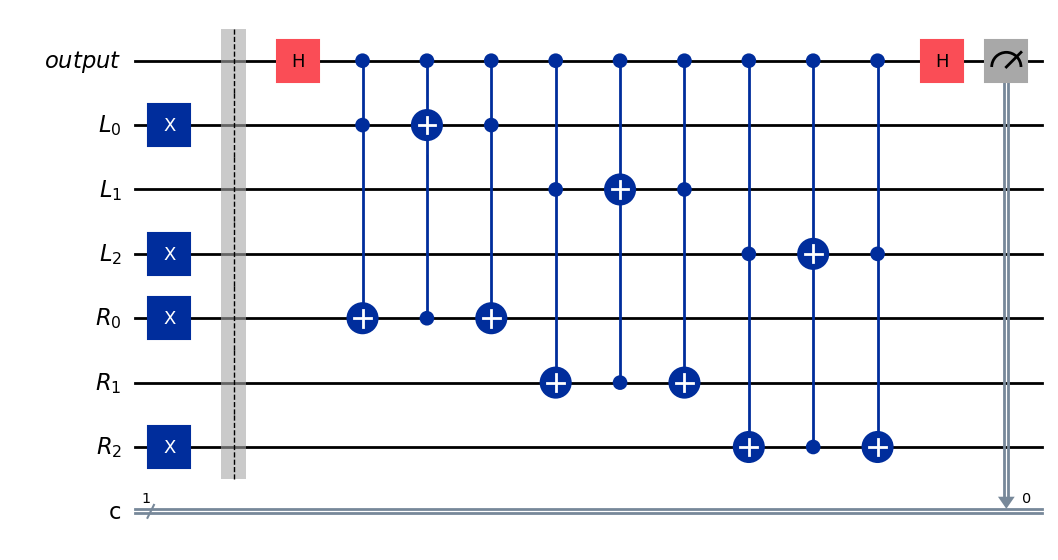

In [ ]:
def build_b1_circuit(k_val: int):
    """
    Builds the SWAP test circuit to compare R=|5> and L=|k_val>.
    """
    # 1 control qubit, 3 for L, 3 for R, 1 classical bit for measurement
    ctrl = QuantumRegister(1, 'output')
    L = QuantumRegister(3, 'L')
    R = QuantumRegister(3, 'R')
    c = ClassicalRegister(1, 'c')

    qc = QuantumCircuit(ctrl, L, R, c)

    # --- State Preparation ---
    # Prepare R = |5> (Binary 101).
    qc.x(R[0])
    qc.x(R[2])

    # Prepare L = |k_val>
    k_bin = format(k_val, '03b')
    if k_bin[2] == '1': qc.x(L[0]) # LSB
    if k_bin[1] == '1': qc.x(L[1])
    if k_bin[0] == '1': qc.x(L[2]) # MSB

    qc.barrier()

    # --- SWAP Test ---
    # 1. Hadamard on control
    qc.h(ctrl[0])

    # 2. Output-controlled exchange across the 3 pairs (L_i, R_i)
    for i in range(3):
        # Controlled-SWAP using three CCX (Toffoli) gates
        qc.ccx(ctrl[0], L[i], R[i])
        qc.ccx(ctrl[0], R[i], L[i])
        qc.ccx(ctrl[0], L[i], R[i])

    # 3. Hadamard on control and measure
    qc.h(ctrl[0])
    qc.measure(ctrl[0], c[0])

    return qc

# Visualize the circuit for k=5
qc_test = build_b1_circuit(k_val=5)
qc_test.draw('mpl')

#### 3. Simulation & Evaluation Protocol

This cell runs the circuit for all possible computational basis states $k \in \{0, \dots, 7\}$ across different shot counts, computing the estimated fidelity $\widehat{F} = 1 - 2P(1)$ and organizing the results into positives ($k=5$) and negatives ($k \neq 5$).

In [ ]:
simulator = AerSimulator()
shots_values = [1000, 2000, 4000]

# Dictionaries to store fidelity results
# Format: {shots: [list of estimated fidelities]}
positives = {s: [] for s in shots_values}
negatives = {s: [] for s in shots_values}

for k in range(8):
    qc = build_b1_circuit(k)
    compiled_qc = transpile(qc, simulator)

    for shots in shots_values:
        job = simulator.run(compiled_qc, shots=shots)
        counts = job.result().get_counts()

        # Calculate P(1)
        count_1 = counts.get('1', 0)
        p1 = count_1 / shots

        # Estimate Fidelity
        f_est = 1 - 2 * p1

        if k == 5:
            positives[shots].append(f_est)
        else:
            negatives[shots].append(f_est)

# --- Print Results Table ---
print("-"*51)
print(f"{'Shots':<8} | {'Type':<10} | {'Mean Fidelity':<15} | {'Std Error'}")
print("-" * 51)

for shots in shots_values:
    # Positives (k=5)
    pos_data = positives[shots]
    pos_mean = np.mean(pos_data)
    pos_se = np.std(pos_data, ddof=1) / np.sqrt(len(pos_data)) if len(pos_data) > 1 else 0.0
    print(f"{shots:<8} | {'Pos (k=5)':<10} | {pos_mean:<15.4f} | {pos_se:.4f}")

    # Negatives (k!=5)
    neg_data = negatives[shots]
    neg_mean = np.mean(neg_data)
    neg_se = np.std(neg_data, ddof=1) / np.sqrt(len(neg_data))
    print(f"{shots:<8} | {'Neg (k!=5)':<10} | {neg_mean:<15.4f} | {neg_se:.4f}")

---------------------------------------------------
Shots    | Type       | Mean Fidelity   | Std Error
---------------------------------------------------
1000     | Pos (k=5)  | 1.0000          | 0.0000
1000     | Neg (k!=5) | 0.0071          | 0.0120
2000     | Pos (k=5)  | 1.0000          | 0.0000
2000     | Neg (k!=5) | 0.0046          | 0.0069
4000     | Pos (k=5)  | 1.0000          | 0.0000
4000     | Neg (k!=5) | 0.0014          | 0.0060


#### 4. Analysis & Discussion

##### Design Discussion
> The control is distributed uniformly across the three qubit pairs using 9 Toffoli (ccx) gates in total (3 per pair). This design strictly avoids high-level abstracted gates (like CSWAP) to demonstrate the underlying standard gate decomposition. The trade-off is an increased circuit depth and higher multi-qubit gate count.
#####How does the true fidelity differ from the estimated fidelity for identical states?
> For identical states ($k=5$), the true fidelity is exactly 1.0. The estimated fidelity in our ideal simulation is also exactly 1.0. Shot noise has no effect here because the SWAP test mathematically guarantees destructive interference for the $\vert{}1\rangle$ state on the output qubit. Since $P(1) = 0$ perfectly, the result is completely deterministic.
#####How does the true fidelity differ from the estimated fidelity for different states?
> For different, orthogonal basis states ($k \neq 5$), the true fidelity is exactly 0.0. However, the estimated fidelity fluctuates slightly around 0.0. This is purely the effect of shot noise. Because the theoretical $P(1)$ is exactly 0.5, each shot is a coin flip. The finite number of samples means we rarely measure exactly 50% ones and 50% zeros. As the number of shots increases (from 1k to 4k), the Standard Error shrinks, bringing the estimated mean closer to the true value of 0.0.

## Task B.2 - Introducing superposition

### Modification

* Keep $R = |5\rangle$. For $L$, after preparing $|k\rangle$, put one left qubit (e.g., $L_0$) into superposition with `qc.h(L_0)` before the SWAP test. This creates a state with non-zero amplitude on two neighboring basis states.

### Rerun & compare

* Rerun the full pipeline (design unchanged). Report estimated fidelities $\widehat{F}$ for positives (k=5) and negatives (k≠5).

### Discussion

* Do some negatives (k≠5) show larger $\widehat{F}$? If yes, explain why. Relate to how fidelity encodes overlap: superposition spreads amplitude, increasing chance overlap with $|5\rangle$.
* Would it still be possible to determine if k=5 using the strategy you proposed in B.1? Explain why, or why not.

### What to include

1. Circuit diagram of your SWAP test (with H – exchange – H, exchange decomposition, helpers if any).
2. Design discussion (1–2 paragraphs): control distribution, and resource trade-offs (depth, two-qubit/three-qubit counts, ...).
3. Answers to all questions in B.1.
4. Answers to all questions in B.2.
5. Reflection: what changed with superposition and one concrete improvement you would try next (e.g., alternate control distribution, or validating with exact inner products on the classical side).

### Our Solution

 #### 1. Circuit Modification

The only change in the circuit is applying a Hadamard gate qc.h(L[0]) to the least significant qubit of the test register $L$ just before the SWAP test begins. This puts the state into a superposition.

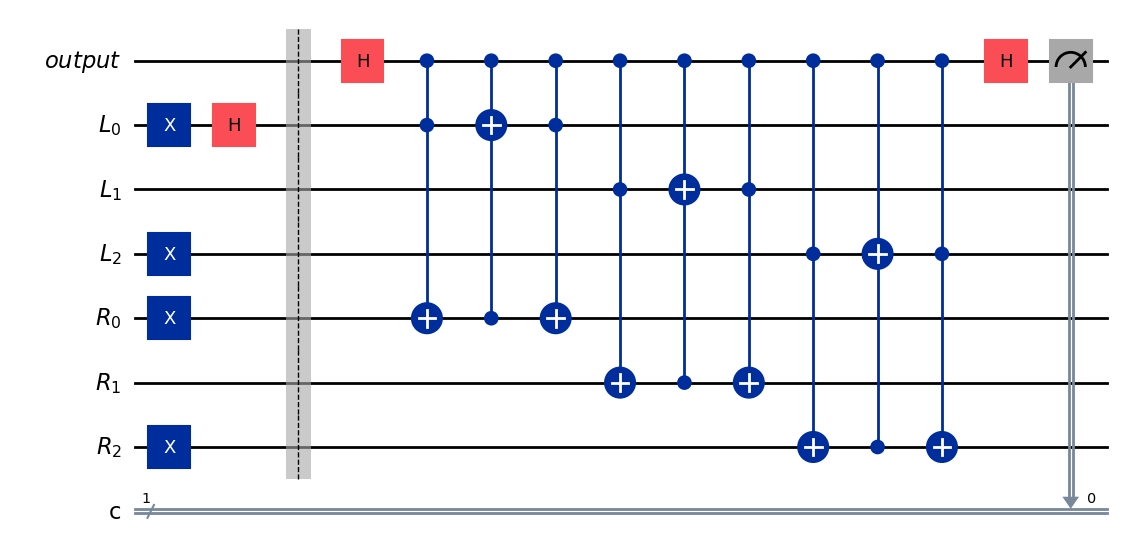

In [ ]:
def build_b2_circuit(k_val):
    """
    Builds the modified SWAP test circuit.
    L[0] is put into superposition before the swap test.
    """
    ctrl = QuantumRegister(1, 'output')
    L = QuantumRegister(3, 'L')
    R = QuantumRegister(3, 'R')
    c = ClassicalRegister(1, 'c')

    qc = QuantumCircuit(ctrl, L, R, c)

    # --- State Preparation ---
    # Prepare R = |5> (101)
    qc.x(R[0])
    qc.x(R[2])

    # Prepare L = |k_val>
    k_bin = format(k_val, '03b')
    if k_bin[2] == '1': qc.x(L[0])
    if k_bin[1] == '1': qc.x(L[1])
    if k_bin[0] == '1': qc.x(L[2])

    # MODIFICATION
    # Put one left qubit into superposition
    qc.h(L[0])

    qc.barrier()

    # --- SWAP Test ---
    qc.h(ctrl[0])

    # Output-controlled exchange
    for i in range(3):
        qc.ccx(ctrl[0], L[i], R[i])
        qc.ccx(ctrl[0], R[i], L[i])
        qc.ccx(ctrl[0], L[i], R[i])

    qc.h(ctrl[0])
    qc.measure(ctrl[0], c[0])

    return qc

# Visualize the modified circuit for k=5
qc_b2_test = build_b2_circuit(5)
qc_b2_test.draw('mpl')

#### 2. Rerun & Compare


We run the exact same evaluation pipeline as B.1, but using our new build_b2_circuit.

In [ ]:
shots_values = [1000, 2000, 4000]

positives_b2 = {s: [] for s in shots_values}
negatives_b2 = {s: [] for s in shots_values}

for k in range(8):
    qc = build_b2_circuit(k)
    compiled_qc = transpile(qc, simulator)

    for shots in shots_values:
        job = simulator.run(compiled_qc, shots=shots)
        counts = job.result().get_counts()

        p1 = counts.get('1', 0) / shots
        f_est = 1 - 2 * p1  # Estimated Fidelity

        if k == 5:
            positives_b2[shots].append(f_est)
        else:
            negatives_b2[shots].append(f_est)

# --- Print Results Table ---
print("Evaluation Protocol Results\n" + "-"*51)
print(f"{'Shots':<8} | {'Type':<10} | {'Mean Fidelity':<15} | {'Std Error'}")
print("-" * 51)

for shots in shots_values:
    # Positives (k=5)
    pos_data = positives_b2[shots]
    pos_mean = np.mean(pos_data)
    pos_se = np.std(pos_data, ddof=1) / np.sqrt(len(pos_data)) if len(pos_data) > 1 else 0.0
    print(f"{shots:<8} | {'Pos (k=5)':<10} | {pos_mean:<15.4f} | {pos_se:.4f}")

    # Negatives (k!=5)
    neg_data = negatives_b2[shots]
    neg_mean = np.mean(neg_data)
    neg_se = np.std(neg_data, ddof=1) / np.sqrt(len(neg_data))
    print(f"{shots:<8} | {'Neg (k!=5)':<10} | {neg_mean:<15.4f} | {neg_se:.4f}")

Evaluation Protocol Results
---------------------------------------------------
Shots    | Type       | Mean Fidelity   | Std Error
---------------------------------------------------
1000     | Pos (k=5)  | 0.5460          | 0.0000
1000     | Neg (k!=5) | 0.0751          | 0.0796
2000     | Pos (k=5)  | 0.5020          | 0.0000
2000     | Neg (k!=5) | 0.0656          | 0.0743
4000     | Pos (k=5)  | 0.4925          | 0.0000
4000     | Neg (k!=5) | 0.0823          | 0.0711


#### 3. Discussion & Analysis

Do some negatives ($k \neq 5$) show larger $\widehat{F}$?
> Yes. For certain negative states (specifically $k=4$, which is 100 in binary), the estimated fidelity jumps from $0$ to approximately $0.5$.Why? The Hadamard gate on $L_0$ places the qubit into a superposition. If we start with $k=4$ ($\vert{}100\rangle$), applying $H$ to $L_0$ transforms the state into $\frac{1}{\sqrt{2}}\vert{}100\rangle + \frac{1}{\sqrt{2}}\vert{}101\rangle$. Because fidelity measures the squared overlap with the reference state $\vert{}5\rangle$ (which is $\vert{}101\rangle$), the probability amplitude of this overlap is $\frac{1}{\sqrt{2}}$. Squaring this amplitude yields a theoretical true fidelity of exactly $0.5$. Superposition literally "spreads" the probability amplitude across adjacent computational basis states, artificially creating an overlap where there was none before.

Would it still be possible to determine if $k=5$ using the strategy you proposed in B.1?
> No, the B.1 strategy (which relied on "if you see a single '1', they are not identical") completely breaks down here. In B.2, even when $k=5$ ($\vert{}101\rangle$), applying the Hadamard gate to $L_0$ changes the state to $\frac{1}{\sqrt{2}}\vert{}100\rangle - \frac{1}{\sqrt{2}}\vert{}101\rangle$. The reference state $R$ remains exactly $\vert{}101\rangle$. The theoretical fidelity between these two states is now $\vert{}-\frac{1}{\sqrt{2}}\vert{}^2 = 0.5$. Because the true fidelity is $0.5$, the expected probability of measuring a '1' is $P(1) = 0.25$. Since $P(1) > 0$, the $k=5$ state will now regularly produce '1's when measured. A deterministic single-shot rule is impossible; you must perform statistical sampling to estimate the mean fidelity and compare numerical thresholds.

#### What changed with superposition:


Introducing superposition transformed the SWAP test from a binary identical/orthogonal check into a continuous similarity measure.

## AI Assistance Disclosure

In compliance with the project's AI policy, this section details the use of generative AI tools in the preparation of this notebook.

### 1. Tools and Models Used
- **Tool/Model**: Gemini 3.5 flash (via Google Colab AI)

### 2. Per-Task Usage
- **Task 1 (State-Vector Simulator & Bell State)**:
  - Used for code refactoring and structure formatting.

- **Task 2 (State-Vector SWAP Test)**:
  - Helped draft the statistical error and standard deviation analysis comparing exact, sampled, and analytical inner-product results.

- **Bonus Exercise (Multiqubit SWAP Test & Superposition)**:
  - Assisted in writing the boilerplate simulation loop over different shot counts and organizing the output into a structured results table.
  - Helped refining discussions on the physics of superposition overlap and how it shifts the SWAP test from a deterministic check to a statistical threshold measurement.

### 3. Summary of Interactions and Prompts
- **Core Prompts**:
  - *"Help format this text cell using clean LaTeX equations and ket notation."*
  - *"Refactor the results visualization and print them out in a formatted text table with standard error calculation."*

### 4. Validation & Adaptation
- All code outputs generated by AI were executed directly in Google Colab to verify correctness.
- We checked the theoretical probability outputs mathematically against analytical expectations.
- We checked Qiskit circuit diagrams visually to confirm correct qubit-to-qubit mappings and control configurations.